# 📘 Predicting Will It Rain Tomorrow Using Machine Learning

In [364]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score

In [365]:
# Load the Dataset
df = pd.read_csv('assignment2_australia_weather.csv')
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


In [366]:
# How many fields are missing.
print(f'Total number of records: {df.shape[0]}')
print(f'Number of missing fields:\n{df.isnull().sum()}')

Total number of records: 142193
Number of missing fields:
Date                 0
Location             0
MinTemp            637
MaxTemp            322
Rainfall          1406
Evaporation      60843
Sunshine         67816
WindGustDir       9330
WindGustSpeed     9270
WindDir9am       10013
WindDir3pm        3778
WindSpeed9am      1348
WindSpeed3pm      2630
Humidity9am       1774
Humidity3pm       3610
Pressure9am      14014
Pressure3pm      13981
Cloud9am         53657
Cloud3pm         57094
Temp9am            904
Temp3pm           2726
RainToday         1406
RISK_MM              0
RainTomorrow         0
dtype: int64


## 📊 Visualize the Dataset

In [367]:
# Remove irrelevant columns
df = df.drop(columns=['Date', 'Location', 'RISK_MM'])
dropped_df = df.dropna().copy()
# Encode categorical variables numerically (label encoding)
for col in dropped_df.select_dtypes(include="string").columns:
    dropped_df[col] = dropped_df[col].astype("category").cat.codes
cleaned.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
5939,17.9,35.2,0.0,12.0,12.3,11,48.0,1,12,6.0,...,20.0,13.0,1006.3,1004.4,2.0,5.0,26.6,33.4,0,0
5940,18.4,28.9,0.0,14.8,13.0,8,37.0,10,10,19.0,...,30.0,8.0,1012.9,1012.1,1.0,1.0,20.3,27.0,0,0
5942,19.4,37.6,0.0,10.8,10.6,5,46.0,5,6,30.0,...,42.0,22.0,1012.3,1009.2,1.0,6.0,28.7,34.9,0,0
5943,21.9,38.4,0.0,11.4,12.2,14,31.0,14,15,6.0,...,37.0,22.0,1012.7,1009.1,1.0,5.0,29.1,35.6,0,0
5944,24.2,41.0,0.0,11.2,8.4,14,35.0,7,14,17.0,...,19.0,15.0,1010.7,1007.4,1.0,6.0,33.6,37.6,0,0


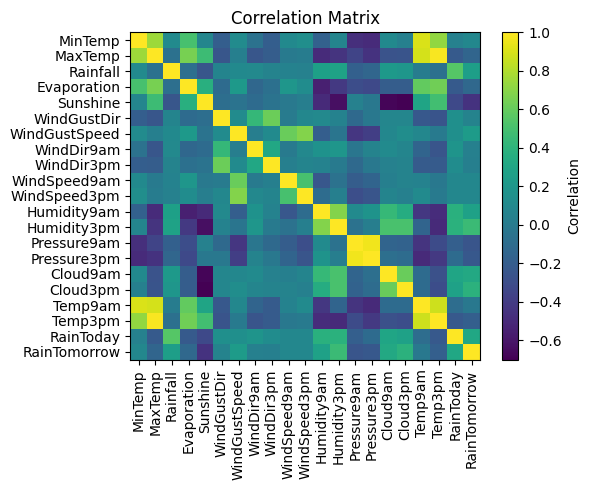

In [368]:
# Generate a correlation matrix
corr = dropped_df.corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [369]:
# Rank correlations
corr['RainTomorrow'].sort_values(ascending=False)

RainTomorrow     1.000000
Humidity3pm      0.455358
Cloud3pm         0.388574
Cloud9am         0.323972
RainToday        0.309098
Humidity9am      0.271033
Rainfall         0.254342
WindGustSpeed    0.233158
WindSpeed3pm     0.088862
MinTemp          0.087428
WindSpeed9am     0.083904
WindGustDir      0.061751
WindDir9am       0.035992
WindDir3pm       0.032203
Temp9am         -0.018179
Evaporation     -0.130002
MaxTemp         -0.147467
Temp3pm         -0.183586
Pressure3pm     -0.230418
Pressure9am     -0.254816
Sunshine        -0.453407
Name: RainTomorrow, dtype: float64

## 🧹 Data Preparation

In [370]:
# Remove exact duplicate rows
df = df.drop_duplicates()
# Fill remaining missing values with median for numeric columns and mode for categorical columns.
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="string").columns:
    if not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])
# Encode categorical variables numerically (label encoding)
for col in df.select_dtypes(include="string").columns:
    df[col] = df[col].astype("category").cat.codes

X = df.drop(columns=['RainTomorrow'])
y = df['RainTomorrow']

## ✂️ Train-Test Split

In [371]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 🤖 Train the Model

In [372]:
def trainer(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prededicted_proba = model.predict_proba(X_test)
    y_pred_prob = model.predict_proba(X_test)[:, 1]
    print(f'{model.__class__.__name__}')
    # Evaluation
    print("Accuracy:", accuracy_score(y_test, y_pred))

    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
    plt.plot(fpr, tpr)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.title('ROC curve for various classifier')
    plt.legend(['LogisticRegression', 'RandomForestClassifier', 'KNeighborsClassifier'])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.grid(True)

    print("AUC score: ", roc_auc_score(y_test, y_pred_prob))

## 🔮 Make Predictions Using Imputed Data Without Scaling

LogisticRegression
Accuracy: 0.8421737601125572
AUC score:  0.8625032736034286
RandomForestClassifier
Accuracy: 0.8546957439324657
AUC score:  0.8814035779523699
KNeighborsClassifier
Accuracy: 0.8351741118536757
AUC score:  0.8179158046296376


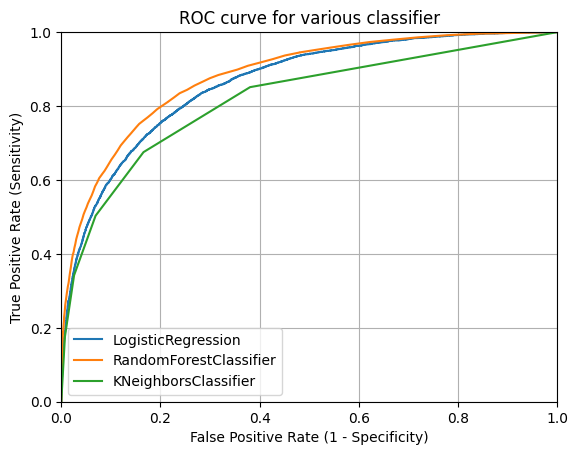

In [373]:
lg_model = LogisticRegression(max_iter=10000)
trainer(lg_model, X_train, y_train, X_test, y_test)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
trainer(rf_model, X_train, y_train, X_test, y_test)
kn_model = KNeighborsClassifier()
trainer(kn_model, X_train, y_train, X_test, y_test)

## 🔮 Make Predictions Using Imputed Data With Scaling

LogisticRegression
Accuracy: 0.8421034118888499
AUC score:  0.862502354572216
RandomForestClassifier
Accuracy: 0.8542384804783679
AUC score:  0.8815927737074432
KNeighborsClassifier
Accuracy: 0.8322898346816743
AUC score:  0.8170804871862827


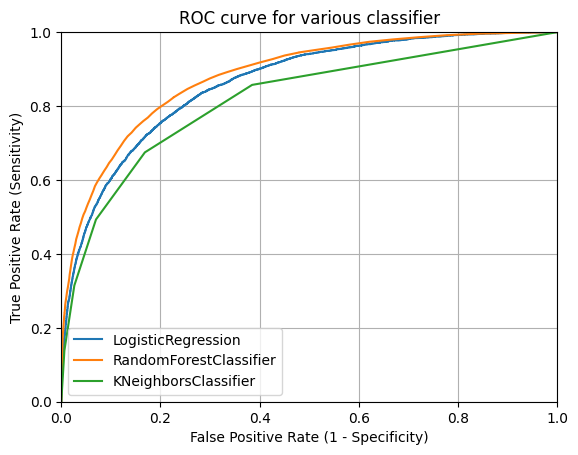

In [374]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

trainer(lg_model, X_train, y_train, X_test, y_test)
trainer(rf_model, X_train, y_train, X_test, y_test)
trainer(kn_model, X_train, y_train, X_test, y_test)

## 🔮 Make Predictions Using Imputed Data With Scaling and Feature Extraction

LogisticRegression
Accuracy: 0.8421034118888499
AUC score:  0.862502354572216
RandomForestClassifier
Accuracy: 0.8542384804783679
AUC score:  0.8815927737074432
KNeighborsClassifier
Accuracy: 0.8322898346816743
AUC score:  0.8170804871862827


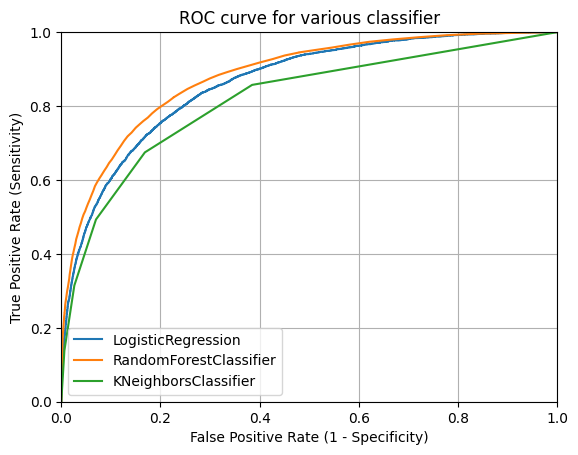

In [375]:
# Temperature-based features
if {"Temp9am", "Temp3pm"}.issubset(df.columns):
    df["temp_change"] = df["Temp3pm"] - df["Temp9am"]
    #df["temp_avg"] = (df["MaxTemp"] + df["MinTemp"]) / 2

# Humidity-based features
if {"Humidity9am", "Humidity3pm"}.issubset(df.columns):
    df["humidity_change"] = df["Humidity3pm"] - df["Humidity9am"]
    #df["humidity_avg"] = (df["Humidity9am"] + df["Humidity3pm"]) / 2

# Pressure-based features
if {"Pressure9am", "Pressure3pm"}.issubset(df.columns):
    df["pressure_change"] = df["Pressure3pm"] - df["Pressure9am"]
    #df["pressure_avg"] = (df["Pressure9am"] + df["Pressure3pm"]) / 2

# Wind-based features
if {"Windspeed9am", "Windspeed3pm"}.issubset(df.columns):
    #df["windspeed_avg"] = (df["Windspeed9am"] + df["Windspeed3pm"]) / 2
    df["windspeed_change"] = df["Windspeed3pm"] - df["Windspeed9am"]

# Cloud-based features
if {"Cloud9am", "Cloud3pm"}.issubset(df.columns):
    #df["cloud_avg"] = (df["Cloud9am"] + df["Cloud3pm"]) / 2
    df["cloud_change"] = df["Cloud3pm"] - df["Cloud9am"]

# Drop the old columns
df.drop(columns=['MaxTemp', 'MinTemp', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm'], inplace=True)

X_train = scaler.inverse_transform(X_train)
X_test = scaler.inverse_transform(X_test)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

trainer(lg_model, X_train, y_train, X_test, y_test)
trainer(rf_model, X_train, y_train, X_test, y_test)
trainer(kn_model, X_train, y_train, X_test, y_test)